Obtain and view datasets

File Paths

In [7]:
import pandas as pd
USER_PRODUCTS_FILE = "processed/user_prior_products.parquet"
PRODUCT_LOOKUP_FILE = "processed/products_lookup.parquet"
OUTPUT_FILE = "processed/user_features.parquet"

Load Data

In [8]:
print("Loading data...")

user_products = pd.read_parquet(USER_PRODUCTS_FILE)
products = pd.read_parquet(PRODUCT_LOOKUP_FILE)

print(f"Users loaded: {len(user_products):,}")
print(f"Products loaded: {len(products):,}")

Loading data...
Users loaded: 206,209
Products loaded: 49,685


Feature Engineering. Keeps only columns required for clustering
Before:

user_id    product_id
1          [196, 14084, 12427, ...]

After:

user_id    product_id
1          196
1          14084
1          12427


In [9]:
user_products = user_products[
    ["user_id", "product_id"]
].copy()

products = products[
    ["product_id", "department"]
].copy()

Expanding (altering) product list

In [10]:
print("Exploding product lists...")

user_products = user_products.explode("product_id")

# Convert product IDs to a consistent numeric type
user_products["product_id"] = pd.to_numeric(
    user_products["product_id"],
    errors="coerce"
)

# Remove invalid product IDs if any exist
user_products = user_products.dropna(subset=["product_id"])

user_products["product_id"] = user_products["product_id"].astype("int64")

Exploding product lists...


Join product to it's department

In [11]:
print("Joining products to departments...")

user_departments = user_products.merge(
    products,
    on="product_id",
    how="left"
)

Joining products to departments...


Handle products w/o a usable department

In [12]:
missing_departments = (
    user_departments["department"].isna()
    | (user_departments["department"] == "missing")
)

print(
    "Products without usable department:",
    f"{missing_departments.sum():,}"
)

user_departments = user_departments.loc[
    ~missing_departments
].copy()

Products without usable department: 41,774


Count unique products per department for each user
 user_id    department       product_count
1          produce          12
1          dairy eggs        7
1          snacks            3


In [13]:
print("Calculating department counts...")

department_counts = (
    user_departments
    .groupby(["user_id", "department"])
    .size()
    .unstack(fill_value=0)
)


Calculating department counts...


Convert count to proportions
We use proportions so users with large purchase histories
are not automatically separated from users with small
purchase histories simply because of their total number
of unique products.

Each row should sum to approximately 1.

In [14]:
print("Converting counts to proportions...")

user_features = department_counts.div(
    department_counts.sum(axis=1),
    axis=0
)

Converting counts to proportions...


Clean column Names

In [15]:
user_features.columns = [
    str(column).strip().lower().replace(" ", "_")
    for column in user_features.columns
]

Convert user_id back from index to column

In [16]:
user_features = user_features.reset_index()

Validation

In [17]:
feature_columns = [
    column
    for column in user_features.columns
    if column != "user_id"
]

row_sums = user_features[feature_columns].sum(axis=1)

print("\nFeature matrix created")
print(f"Users: {len(user_features):,}")
print(f"Features: {len(feature_columns):,}")

print("\nDepartment features:")
print(feature_columns)

print("\nFirst five users:")
print(user_features.head())

print("\nRow sum statistics:")
print(row_sums.describe())

print("\nMissing values:")
print(user_features.isna().sum())


Feature matrix created
Users: 206,209
Features: 20

Department features:
['alcohol', 'babies', 'bakery', 'beverages', 'breakfast', 'bulk', 'canned_goods', 'dairy_eggs', 'deli', 'dry_goods_pasta', 'frozen', 'household', 'international', 'meat_seafood', 'other', 'pantry', 'personal_care', 'pets', 'produce', 'snacks']

First five users:
   user_id   alcohol  babies    bakery  beverages  breakfast  bulk  \
0        1  0.000000     0.0  0.000000   0.111111   0.055556   0.0   
1        2  0.000000     0.0  0.019608   0.058824   0.029412   0.0   
2        3  0.000000     0.0  0.000000   0.060606   0.000000   0.0   
3        4  0.117647     0.0  0.117647   0.176471   0.000000   0.0   
4        5  0.000000     0.0  0.000000   0.000000   0.000000   0.0   

   canned_goods  dairy_eggs      deli  ...    frozen  household  \
0      0.000000    0.277778  0.000000  ...  0.000000   0.055556   
1      0.009804    0.176471  0.117647  ...  0.117647   0.000000   
2      0.000000    0.181818  0.030303  ..

Save feature Matrix

In [18]:
user_features.to_parquet(
    OUTPUT_FILE,
    index=False
)

print(f"\nSaved feature matrix to: {OUTPUT_FILE}")


Saved feature matrix to: processed/user_features.parquet


If a user's unique products consisted of:

Plain Text
10 produce products
5 dairy/egg products
3 snack products
2 beverage products

we don't want:

Plain Text
produce = 10
dairy_eggs = 5
snacks = 3
beverages = 2

Instead the script produces:

Plain Text
produce = 0.50
dairy_eggs = 0.25
snacks = 0.15
beverages = 0.10

That example is illustrative, not a value from the dataset.

This normalization matters because the actual user_prior_products sample shows that the size of users' product histories varies substantially.

So rather than creating roughly:

Plain Text
customer × every individual product

we're creating:

Plain Text
customer × department

Load the feature matrix

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import time

# All columns are clustering features
feature_columns = user_features.columns.tolist()

# Convert dataframe to NumPy matrix
X = user_features.to_numpy(dtype=float)

print("Number of users:", X.shape[0])
print("Number of features:", X.shape[1])
print("Missing values:", np.isnan(X).sum())

print("\nFeatures:")
print(feature_columns)

print("\nFirst user feature vector:")
print(X[0])

print("\nRow sums:")
print(X.sum(axis=1)[:10])


Number of users: 206209
Number of features: 21
Missing values: 0

Features:
['user_id', 'alcohol', 'babies', 'bakery', 'beverages', 'breakfast', 'bulk', 'canned_goods', 'dairy_eggs', 'deli', 'dry_goods_pasta', 'frozen', 'household', 'international', 'meat_seafood', 'other', 'pantry', 'personal_care', 'pets', 'produce', 'snacks']

First user feature vector:
[1.         0.         0.         0.         0.11111111 0.05555556
 0.         0.         0.27777778 0.         0.         0.
 0.05555556 0.         0.         0.         0.05555556 0.
 0.         0.22222222 0.22222222]

Row sums:
[ 2.  3.  4.  5.  6.  7.  8.  9. 10. 11.]


Euclidean Distance

In [20]:
def euclidean_distance(point1, point2):
    return np.sqrt(np.sum((point1 - point2) ** 2))

Farthest first initialization

In [21]:
def farthest_first_initialization(X, k, random_state=42):
    rng = np.random.default_rng(random_state)

    # Pick first centroid randomly
    first_index = rng.integers(0, X.shape[0])

    centroid_indices = [first_index]
    centroids = [X[first_index].copy()]

    while len(centroids) < k:

        current_centroids = np.array(centroids)

        # Calculate distance from every point to every selected centroid
        distances = np.linalg.norm(
            X[:, np.newaxis, :] -
            current_centroids[np.newaxis, :, :],
            axis=2
        )

        # For each point, find its distance to its nearest centroid
        min_distances = distances.min(axis=1)

        # Prevent already-selected points from being selected again
        min_distances[centroid_indices] = -1

        # Pick point farthest from its nearest existing centroid
        next_index = np.argmax(min_distances)

        centroid_indices.append(next_index)
        centroids.append(X[next_index].copy())

    return np.array(centroids)

Assign each user to the nearest centroid

In [22]:
def assign_clusters(X, centroids):
    distances = np.linalg.norm(
        X[:, np.newaxis, :] -
        centroids[np.newaxis, :, :],
        axis=2
    )

    labels = np.argmin(distances, axis=1)

    return labels

Update the centroids

In [23]:
def update_centroids(X, labels, k, old_centroids):
    new_centroids = np.zeros_like(old_centroids)

    for cluster_id in range(k):

        cluster_points = X[labels == cluster_id]

        if len(cluster_points) > 0:
            new_centroids[cluster_id] = cluster_points.mean(axis=0)

        else:
            # If no users were assigned to this cluster,
            # retain its previous centroid
            new_centroids[cluster_id] = old_centroids[cluster_id]

    return new_centroids

Complete K-Means

In [24]:
def kmeans(
    X,
    k,
    max_iterations=100,
    tolerance=1e-6,
    random_state=42
):
    # Initialize centroids
    centroids = farthest_first_initialization(
        X,
        k,
        random_state
    )

    start_time = time.perf_counter()

    for iteration in range(max_iterations):

        # 1. Assign points to nearest centroid
        labels = assign_clusters(X, centroids)

        # 2. Recalculate centroids
        new_centroids = update_centroids(
            X,
            labels,
            k,
            centroids
        )

        # 3. Determine how much the centroids moved
        centroid_shift = np.linalg.norm(
            new_centroids - centroids
        )

        # 4. Replace old centroids
        centroids = new_centroids

        # 5. Check convergence
        if centroid_shift < tolerance:
            break

    # Final assignment using final centroids
    labels = assign_clusters(X, centroids)

    runtime = time.perf_counter() - start_time

    return labels, centroids, iteration + 1, runtime


First clustering

In [25]:
k = 4

labels, centroids, iterations, runtime = kmeans(
    X,
    k=k,
    random_state=42
)

print(f"k: {k}")
print(f"Iterations: {iterations}")
print(f"Runtime: {runtime:.4f} seconds")

unique_clusters, cluster_sizes = np.unique(
    labels,
    return_counts=True
)

print("\nCluster sizes:")

for cluster_id, size in zip(unique_clusters, cluster_sizes):
    print(f"Cluster {cluster_id}: {size:,} users")

k: 4
Iterations: 56
Runtime: 8.9497 seconds

Cluster sizes:
Cluster 0: 51,551 users
Cluster 1: 51,553 users
Cluster 2: 51,553 users
Cluster 3: 51,552 users


Sanity Check

In [26]:
print("\nTotal clustered users:", cluster_sizes.sum())
print("Total users in X:", X.shape[0])

assert cluster_sizes.sum() == X.shape[0]



Total clustered users: 206209
Total users in X: 206209


Within cluster variation

In [27]:
def calculate_wcss(X, labels, centroids):
    wcss = 0.0

    for cluster_id in range(len(centroids)):

        cluster_points = X[labels == cluster_id]

        squared_distances = np.sum(
            (cluster_points - centroids[cluster_id]) ** 2,
            axis=1
        )

        wcss += np.sum(squared_distances)

    return wcss

In [28]:
wcss = calculate_wcss(
    X,
    labels,
    centroids
)

print(f"WCSS: {wcss:.6f}")

WCSS: 45669012410494.921875


Elbow Experiment, 2 -> 10

In [29]:
k_values = range(2, 11)

results = []

for k in k_values:

    labels_k, centroids_k, iterations_k, runtime_k = kmeans(
        X,
        k=k,
        random_state=42
    )

    wcss_k = calculate_wcss(
        X,
        labels_k,
        centroids_k
    )

    results.append({
        "k": k,
        "wcss": wcss_k,
        "iterations": iterations_k,
        "runtime": runtime_k
    })

    print(
        f"k={k}: "
        f"WCSS={wcss_k:.6f}, "
        f"iterations={iterations_k}, "
        f"runtime={runtime_k:.4f}s"
    )

k=2: WCSS=182676049512743.062500, iterations=16, runtime=1.1941s
k=3: WCSS=81189355413527.500000, iterations=33, runtime=3.1398s
k=4: WCSS=45669012410494.921875, iterations=56, runtime=7.8953s
k=5: WCSS=29228168072670.359375, iterations=82, runtime=13.7476s
k=6: WCSS=20297341504117.761719, iterations=100, runtime=20.6847s
k=7: WCSS=14912331084945.224609, iterations=100, runtime=51.6416s
k=8: WCSS=11417260651941.328125, iterations=100, runtime=60.5112s


KeyboardInterrupt: 

Turn results into dataframe

In [30]:
kmeans_results = pd.DataFrame(results)

kmeans_results

,k,wcss,iterations,runtime
0,2,1.826760e+14,16,1.194104
1,3,8.118936e+13,33,3.139753
2,4,4.566901e+13,56,7.895264
3,5,2.922817e+13,82,13.747591
4,6,2.029734e+13,100,20.684699
5,7,1.491233e+13,100,51.641552
6,8,1.141726e+13,100,60.511196


Plot elbow

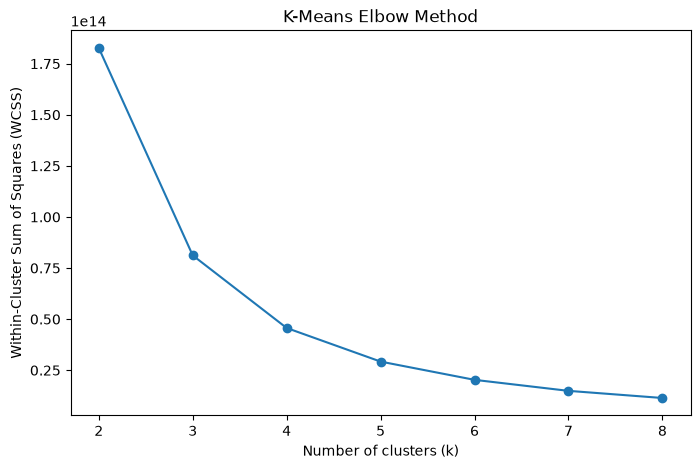

In [31]:
plt.figure(figsize=(8, 5))

plt.plot(
    kmeans_results["k"],
    kmeans_results["wcss"],
    marker="o"
)

plt.xlabel("Number of clusters (k)")
plt.ylabel("Within-Cluster Sum of Squares (WCSS)")
plt.title("K-Means Elbow Method")

plt.xticks(kmeans_results["k"])

plt.show()

Final K Means Run

In [ ]:
FINAL_K = 4

labels, centroids, iterations, runtime = kmeans(
    X,
    k=FINAL_K,
    max_iterations=100,
    tolerance=1e-6,
    random_state=42
)

final_wcss = calculate_wcss(
    X,
    labels,
    centroids
)

print("Final K-Means Model")
print("--------------------")
print(f"k: {FINAL_K}")
print(f"Iterations: {iterations}")
print(f"Runtime: {runtime:.4f} seconds")
print(f"WCSS: {final_wcss:.6f}")

unique_clusters, cluster_sizes = np.unique(
    labels,
    return_counts=True
)

print("\nCluster sizes:")

for cluster_id, size in zip(unique_clusters, cluster_sizes):
    print(f"Cluster {cluster_id}: {size:,} users")

print(f"\nTotal users clustered: {len(labels):,}")

Final K-Means Model
--------------------
k: 3
Iterations: 100
Runtime: 8.0421 seconds
WCSS: 12094.531855

Cluster sizes:
Cluster 0: 67,319 users
Cluster 1: 34,237 users
Cluster 2: 104,653 users

Total users clustered: 206,209


Add cluster assignments to dataframe

In [ ]:
user_features_clustered = user_features.copy()

user_features_clustered["cluster"] = labels

user_features_clustered.head()

,alcohol,babies,bakery,beverages,breakfast,bulk,canned goods,dairy eggs,deli,dry goods pasta,...,household,international,meat seafood,other,pantry,personal care,pets,produce,snacks,cluster
0,0.000000,0.0,0.000000,0.111111,0.055556,0.0,0.000000,0.277778,0.000000,0.000000,...,0.055556,0.000000,0.000000,0.0,0.055556,0.000000,0.0,0.222222,0.222222,2
1,0.000000,0.0,0.019608,0.058824,0.029412,0.0,0.009804,0.176471,0.117647,0.000000,...,0.000000,0.019608,0.009804,0.0,0.068627,0.009804,0.0,0.156863,0.205882,2
2,0.000000,0.0,0.000000,0.060606,0.000000,0.0,0.000000,0.181818,0.030303,0.030303,...,0.030303,0.000000,0.000000,0.0,0.060606,0.000000,0.0,0.363636,0.151515,0
3,0.117647,0.0,0.117647,0.176471,0.000000,0.0,0.058824,0.000000,0.117647,0.000000,...,0.117647,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.117647,0.058824,1
4,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.043478,0.173913,0.043478,0.043478,...,0.000000,0.043478,0.000000,0.0,0.086957,0.000000,0.0,0.434783,0.043478,0


Save final centroids

In [ ]:
centroid_df = pd.DataFrame(
    centroids,
    columns=feature_columns
)

centroid_df.index.name = "cluster"

centroid_df

,alcohol,babies,bakery,beverages,breakfast,bulk,canned goods,dairy eggs,deli,dry goods pasta,frozen,household,international,meat seafood,other,pantry,personal care,pets,produce,snacks
cluster,,,,,,,,,,,,,,,,,,,,
0,0.001980,0.005412,0.025508,0.050924,0.015217,0.001532,0.038461,0.120985,0.027532,0.026250,0.051192,0.016500,0.009780,0.024275,0.001012,0.071416,0.011349,0.000808,0.440069,0.059800
1,0.024714,0.006933,0.027610,0.203436,0.031459,0.000795,0.018012,0.097333,0.024082,0.014786,0.061546,0.087835,0.006090,0.010959,0.002909,0.060825,0.046336,0.005504,0.076463,0.192373
2,0.006252,0.013428,0.038899,0.065862,0.026215,0.000818,0.044661,0.158386,0.034343,0.037990,0.093829,0.033804,0.012187,0.025259,0.001615,0.096641,0.023061,0.003543,0.198903,0.084304


Largest centroid value

In [ ]:
for cluster_id in range(FINAL_K):
    
    print(f"\nCluster {cluster_id}")
    print("--------------------")
    
    top_departments = (
        centroid_df
        .loc[cluster_id]
        .sort_values(ascending=False)
        .head(5)
    )
    
    print(top_departments)


Cluster 0
--------------------
produce       0.440069
dairy eggs    0.120985
pantry        0.071416
snacks        0.059800
frozen        0.051192
Name: 0, dtype: float64

Cluster 1
--------------------
beverages     0.203436
snacks        0.192373
dairy eggs    0.097333
household     0.087835
produce       0.076463
Name: 1, dtype: float64

Cluster 2
--------------------
produce       0.198903
dairy eggs    0.158386
pantry        0.096641
frozen        0.093829
snacks        0.084304
Name: 2, dtype: float64


The final K-means model identified three customer segments based on department-level proportions of unique previously purchased products. Cluster 0 was strongly produce-focused, with produce accounting for approximately 44.0% of its centroid. Cluster 1 was characterized primarily by beverages and snacks, representing approximately 20.3% and 19.2% of its centroid, respectively, and also had the highest household-product proportion. Cluster 2 exhibited a broader mixed-basket profile, led by produce, dairy and eggs, pantry, frozen, and snacks. These labels describe the observed purchasing distributions and do not imply customer demographics, motivations, or nutritional preferences.

Quick Summary to point

Instacart product history
          ↓
Product → department lookup
          ↓
Department proportions per customer
          ↓
20-dimensional Euclidean vectors
          ↓
Farthest-first K-means
          ↓
Elbow experiment
          ↓
Selected k = 3
          ↓
Final customer segmentation
          ↓
 ┌──────────────┬─────────────────────┬─────────────────┐
 │              │                     │                 │
Produce-     Beverage/snack/       Broad mixed-
focused      household-focused     basket

Entire summary to point

1. Established the clustering approach

Based on the ENSF 612 proposal, project guidelines, and clustering lectures, we decided to use:

K-means → BFR → MapReduce

K-means serves as the in-memory baseline, BFR will address scalable/disk-resident clustering, and MapReduce will explore distributed/chunk-based processing. The course specifically presents K-means and BFR as Euclidean clustering approaches and later introduces clustering with MapReduce.

2. Examined the preprocessed Instacart data

We looked at samples from:

user_prior_products.parquet, containing each user's unique previously purchased product IDs.
products_lookup.parquet, mapping products to aisles and departments.

From this, we decided each customer should be one data point, rather than treating users as dimensions.

3. Engineered customer features

Instead of creating one dimension for every individual product, we represented each user using their purchasing distribution across Instacart departments.

For example:

Plain Text
produce dairy eggs snacks beverages ...
User A 0.32 0.18 0.12 0.10
User B 0.08 0.10 0.23 0.25

We used proportions rather than raw counts so customers with large product histories would not automatically appear farther apart simply because they purchased more unique products.

The resulting data contains 20 department features.

4. Implemented K-means ourselves

Rather than simply calling sklearn.KMeans, we implemented the important parts ourselves because the project guidelines emphasize algorithmic design rather than merely running an existing ML function.

We implemented:

Plain Text
Farthest-first centroid initialization
↓
Euclidean distance
↓
Assign user to nearest centroid
↓
Recalculate cluster centroids
↓
Repeat until convergence

This follows the procedure taught in Lecture 16.

5. Used farthest-first initialization

The first centroid was selected randomly.

Each subsequent centroid was selected as the point whose distance to its nearest existing centroid was largest.

This was specifically one of the initialization approaches taught in Lecture 16.

6. Evaluated different values of kkk

We ran K-means for:

k=2,3,…,10k=2,3,\ldots,10k=2,3,…,10

and calculated within-cluster sum of squares (WCSS) for each.

Some important results were:

Plain Text
k = 2: WCSS = 13391.623
k = 3: WCSS = 12094.532
k = 4: WCSS = 11762.294

Going from k=2k=2k=2 to k=3k=3k=3 reduced WCSS by approximately 9.69%, whereas going from k=3k=3k=3 to k=4k=4k=4 reduced it by only approximately 2.75%.

We therefore selected:

k=3\boxed{k=3}k=3​

as a pragmatic elbow-based choice.

We also noted an important limitation: several higher-kkk experiments reached the 100-iteration limit and the later WCSS reductions were irregular. We won't hide that in the report. We'll explain that centroid initialization/convergence influenced the experiment and therefore the elbow was not perfectly clean.

That aligns with the lecture's recommendation to look for the point where increasing kkk begins producing relatively little additional improvement.

7. Ran the final k=3k=3k=3 model

We then clustered the complete customer feature matrix into three customer segments and examined each cluster's centroid.

The three resulting customer profiles were:

Cluster 0: Produce-focused

Plain Text
Produce 44.01%
Dairy/eggs 12.10%
Pantry 7.14%
Snacks 5.98%
Frozen 5.12%

Cluster 1: Beverage/snack/household-focused

Plain Text
Beverages 20.34%
Snacks 19.24%
Dairy/eggs 9.73%
Household 8.78%
Produce 7.65%

Cluster 2: Broad mixed-basket

Plain Text
Produce 19.89%
Dairy/eggs 15.84%
Pantry 9.66%
Frozen 9.38%
Snacks 8.43%

So importantly, K-means gave us clusters that are interpretable in terms of purchasing behaviour, not simply mathematical cluster numbers.

